### Vehicle Combined MPG Prediction Using Machine Learning

####  Project Overview

The goal of this project is to predict **Combined MPG (Miles Per Gallon)** using vehicle specifications such as engine characteristics, fuel type, transmission, drive type, vehicle class, manufacturer, CO₂ emissions, and annual fuel consumption.

This project follows a complete Machine Learning workflow, including:

- Exploratory Data Analysis (EDA)
- Data Cleaning & Feature Engineering
- Data Preprocessing using
- ColumnTransformer + One-Hot Encoding
- Model Training (Linear, Ridge, Lasso & ElasticNet Regression)
- Model Evaluation & Comparison
- Combined MPG Prediction on New Vehicle Data

#### Step 1: Import Liabraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


#### Step 2: Load the Dataset

In [2]:
df=pd.read_csv(r"D:\Imarticus\Ml projects\Regression\Vehicle_MPG\vehicles_mpg.csv")

#### Step 3: Understand the Dataset

In [3]:
df.head()

,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,...,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
0,15.695714,0.0,0.0,0.0,19,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
1,29.964545,0.0,0.0,0.0,9,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
2,12.207778,0.0,0.0,0.0,23,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
3,29.964545,0.0,0.0,0.0,10,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
4,17.347895,0.0,0.0,0.0,17,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0


In [4]:
df.tail()


,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,...,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
39176,23.886563,0.0,0.0,0.0,15,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
39177,10.987000,0.0,0.0,0.0,27,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
39178,21.974000,0.0,0.0,0.0,14,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
39179,16.480500,0.0,0.0,0.0,17,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
39180,16.480500,0.0,0.0,0.0,18,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0


In [5]:
print("Rows and Columns :", df.shape)

Rows and Columns : (39181, 83)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39181 entries, 0 to 39180
Data columns (total 83 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   barrels08        39061 non-null  float64
 1   barrelsA08       39181 non-null  float64
 2   charge120        39181 non-null  float64
 3   charge240        39181 non-null  float64
 4   city08           39181 non-null  int64  
 5   city08U          39181 non-null  float64
 6   cityA08          39181 non-null  int64  
 7   cityA08U         39181 non-null  float64
 8   cityCD           39181 non-null  float64
 9   cityE            39181 non-null  float64
 10  cityUF           39181 non-null  float64
 11  co2              39181 non-null  int64  
 12  co2A             39181 non-null  int64  
 13  co2TailpipeAGpm  39181 non-null  float64
 14  co2TailpipeGpm   39061 non-null  float64
 15  comb08           39181 non-null  int64  
 16  comb08U          39181 non-null  float64
 17  combA08     

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
barrels08,39061.0,17.430109,4.606010,-5.0,14.330870,17.347895,20.115000,47.087143
barrelsA08,39181.0,0.219056,1.143120,0.0,0.000000,0.000000,0.000000,18.311667
charge120,39181.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
charge240,39181.0,0.029570,0.486912,0.0,0.000000,0.000000,0.000000,12.000000
city08,39181.0,18.076593,6.965592,6.0,15.000000,17.000000,20.000000,150.000000
city08U,39181.0,5.037787,10.458016,0.0,0.000000,0.000000,0.000000,150.000000
cityA08,39181.0,0.569485,4.294054,0.0,0.000000,0.000000,0.000000,145.000000
cityA08U,39181.0,0.415593,4.089894,0.0,0.000000,0.000000,0.000000,145.083500
cityCD,39181.0,0.000559,0.045346,0.0,0.000000,0.000000,0.000000,5.350000
cityE,39181.0,0.224722,3.177661,0.0,0.000000,0.000000,0.000000,122.000000


In [8]:
df.describe(include="all")

,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,...,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
count,39061.000000,39181.000000,39181.0,39181.000000,39181.000000,39181.000000,39181.000000,39181.000000,39181.000000,39181.000000,...,8304,53,39181.000000,51,39181,39181,7419,39181.000000,39181.000000,39181.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,46,5,NaN,4,195,68,2,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,GMX,standard charger,NaN,80 amp dual charger,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,N,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1256,42,NaN,42,34268,29503,5186,NaN,NaN,NaN
mean,17.430109,0.219056,0.0,0.029570,18.076593,5.037787,0.569485,0.415593,0.000559,0.224722,...,NaN,NaN,0.005857,NaN,NaN,NaN,NaN,0.094510,0.094076,0.093949
std,4.606010,1.143120,0.0,0.486912,6.965592,10.458016,4.294054,4.089894,0.045346,3.177661,...,NaN,NaN,0.165230,NaN,NaN,NaN,NaN,2.277153,2.188881,2.224230
min,-5.000000,0.000000,0.0,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000
25%,14.330870,0.000000,0.0,0.000000,15.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000
50%,17.347895,0.000000,0.0,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000
75%,20.115000,0.000000,0.0,0.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000


#### Step 4: Data Cleaning

**Duplicate Record Analysis**

Before cleaning the dataset, it is important to check for duplicate records.

Duplicate records can occur due to data entry errors, data integration from multiple sources, or repeated observations. Such records may introduce bias during model training because the same information is counted multiple times.

In this step, we identify duplicate rows in the dataset. We will inspect them before deciding whether they should be removed.

In [9]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print(f"Number of Duplicate Rows: {duplicate_count}")

Number of Duplicate Rows: 71


The dataset contains **71 duplicate records**.

Since these records contain identical information across all columns, they do not contribute any new information to the analysis. Retaining duplicate records may introduce bias into the machine learning model by giving repeated observations more importance.

Therefore, these duplicate rows will be removed before proceeding with further preprocessing.

In [10]:
df.drop_duplicates(inplace=True)
print("After removing duplicates the record is:",df.shape)
print("Duplicated rows:",df.duplicated().sum())

After removing duplicates the record is: (39110, 83)
Duplicated rows: 0


"Duplicate records do not add new information to the dataset. Instead, they can bias the machine learning model by overrepresenting certain  
 observations. Therefore, I removed all true duplicate records before performing further preprocessing."

#### Data cleaning

##### Missing Value Analysis

Missing values are one of the most common data quality issues in machine learning projects. They may occur due to data entry errors, unavailable information, or system limitations.

Before handling missing values, it is important to identify:
- Which columns contain missing values.
- How many missing values are present.
- The percentage of missing values in each column.

This analysis helps us choose an appropriate treatment strategy, such as removing records, imputing values, or dropping features.

In [11]:
missing_values= df.isnull().sum()
missing_values[missing_values>0]

barrels08           120
co2TailpipeGpm      120
cylinders           265
displ               263
drive              1303
eng_dscr          15672
fuelCost08          120
fuelType1           120
make                120
trany               131
VClass              120
guzzler           36774
trans_dscr        24059
tCharger          33291
sCharger          38372
atvType           35903
fuelType2         37618
rangeA            37623
evMotor           38466
mfrCode           30818
c240Dscr          39057
c240bDscr         39059
startStop         31702
dtype: int64

In [12]:
# Missing Value Summary
missing_df = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": round((df.isnull().sum() / len(df)) * 100, 2)
})

# Display only columns with missing values
missing_df = missing_df[missing_df["Missing Values"] > 0]

# Sort by highest missing values
missing_df.sort_values(by="Missing Values", ascending=False)

,Missing Values,Percentage (%)
c240bDscr,39059,99.87
c240Dscr,39057,99.86
evMotor,38466,98.35
sCharger,38372,98.11
rangeA,37623,96.20
fuelType2,37618,96.19
guzzler,36774,94.03
atvType,35903,91.80
tCharger,33291,85.12
startStop,31702,81.06


The missing value analysis shows that several columns contain a very high percentage of missing values (greater than 50%). Since these features are not relevant to the business objective of predicting combined fuel economy (`comb08`), they will not be considered further in the project.

The selected features for this regression model contain only a small percentage of missing values (less than 5%), making them suitable for imputation during the preprocessing stage.

#### Feature Selection

The original EPA Vehicle dataset contains **83 features**. However, not all features are relevant to predicting the target variable (`comb08`).

Before building the machine learning model, only the features that are directly related to vehicle specifications and fuel efficiency were selected.

This helps to:

- Reduce model complexity.
- Improve model interpretability.
- Remove irrelevant and redundant features.
- Reduce preprocessing time.

| Feature            | Description                  | Keep?    | Reason                                                           |
| ------------------ | ---------------------------- | -------- | ---------------------------------------------------------------- |
| **comb08**         | Combined Fuel Economy (MPG)  | ✅ Target | Variable to predict                                              |
| **cylinders**      | Number of engine cylinders   | ✅        | Engine size influences fuel efficiency                           |
| **displ**          | Engine displacement (Liters) | ✅        | Larger engines generally consume more fuel                       |
| **year**           | Manufacturing year           | ✅        | Newer vehicles are generally more fuel efficient                 |
| **drive**          | Drive type                   | ✅        | AWD/FWD/RWD affect fuel consumption                              |
| **trany**          | Transmission                 | ✅        | Transmission influences mileage                                  |
| **fuelType1**      | Primary fuel type            | ✅        | Petrol, Diesel, Hybrid, Electric                                 |
| **VClass**         | Vehicle class                | ✅        | SUVs, Sedans, Trucks have different mileage                      |
| **make**           | Manufacturer                 | ✅        | Different manufacturers use different technologies               |
| **co2TailpipeGpm** | Tailpipe CO₂ emissions       | ✅*       | Used for learning; we'll later discuss its relationship with MPG |
| **fuelCost08**     | Annual fuel cost             | ✅*       | Useful for learning; relationship with MPG will be discussed     |
| **barrels08**      | Annual fuel consumption      | ✅*       | Useful for learning; relationship with MPG will be discussed     |


##### Select the Features

In [13]:
selected_columns = [
    "comb08",
    "cylinders",
    "displ",
    "year",
    "drive",
    "trany",
    "fuelType1",
    "VClass",
    "make",
    "co2TailpipeGpm",
    "fuelCost08",
    "barrels08"
]

df = df[selected_columns]

In [14]:
print("Shape after Feature Selection :", df.shape)

df.head()

Shape after Feature Selection : (39110, 12)


,comb08,cylinders,displ,year,drive,trany,fuelType1,VClass,make,co2TailpipeGpm,fuelCost08,barrels08
0,21,4.0,2.0,1985,Rear-Wheel Drive,Manual 5-spd,Regular Gasoline,Two Seaters,Alfa Romeo,423.190476,1900.0,15.695714
1,11,12.0,4.9,1985,Rear-Wheel Drive,Manual 5-spd,Regular Gasoline,Two Seaters,Ferrari,807.909091,3650.0,29.964545
2,27,4.0,2.2,1985,Front-Wheel Drive,Manual 5-spd,Regular Gasoline,Subcompact Cars,Dodge,329.148148,1500.0,12.207778
3,11,8.0,5.2,1985,Rear-Wheel Drive,Automatic 3-spd,Regular Gasoline,Vans,Dodge,807.909091,3650.0,29.964545
4,19,4.0,2.2,1993,4-Wheel or All-Wheel Drive,Manual 5-spd,Premium Gasoline,Compact Cars,Subaru,467.736842,2500.0,17.347895


The dataset has been successfully reduced from **83 features to 12 relevant features**.

The selected features are directly associated with vehicle specifications and fuel efficiency,  
making them suitable for developing the regression model. Removing unnecessary columns simplifies the preprocessing pipeline and improves the readability of the project.

##### Rename Columns

The selected features have abbreviated names in the original dataset. To improve readability and make the notebook easier to understand, the columns are renamed with more meaningful and descriptive names.

Renaming columns improves code readability, visualization labels, and overall project documentation without changing the underlying data.

In [15]:
# Rename columns
df.rename(columns={
    "comb08": "combined_mpg",
    "cylinders": "engine_cylinders",
    "displ": "engine_displacement",
    "year": "model_year",
    "drive": "drive_type",
    "trany": "transmission",
    "fuelType1": "fuel_type",
    "VClass": "vehicle_class",
    "make": "manufacturer",
    "co2TailpipeGpm": "co2_emission",
    "fuelCost08": "annual_fuel_cost",
    "barrels08": "annual_fuel_consumption"
}, inplace=True)

In [16]:
df

,combined_mpg,engine_cylinders,engine_displacement,model_year,drive_type,transmission,fuel_type,vehicle_class,manufacturer,co2_emission,annual_fuel_cost,annual_fuel_consumption
0,21,4.0,2.0,1985,Rear-Wheel Drive,Manual 5-spd,Regular Gasoline,Two Seaters,Alfa Romeo,423.190476,1900.0,15.695714
1,11,12.0,4.9,1985,Rear-Wheel Drive,Manual 5-spd,Regular Gasoline,Two Seaters,Ferrari,807.909091,3650.0,29.964545
2,27,4.0,2.2,1985,Front-Wheel Drive,Manual 5-spd,Regular Gasoline,Subcompact Cars,Dodge,329.148148,1500.0,12.207778
3,11,8.0,5.2,1985,Rear-Wheel Drive,Automatic 3-spd,Regular Gasoline,Vans,Dodge,807.909091,3650.0,29.964545
4,19,4.0,2.2,1993,4-Wheel or All-Wheel Drive,Manual 5-spd,Premium Gasoline,Compact Cars,Subaru,467.736842,2500.0,17.347895
...,...,...,...,...,...,...,...,...,...,...,...,...
39141,22,4.0,2.0,2007,front-wheel drive,Automatic 4-spd,Regular Gasoline,Small Station Wagons,Suzuki,403.954545,1850.0,14.982273
39150,25,6.0,3.5,2017,All-Wheel Drive,Automatic (S9),Premium Gasoline,Compact Cars,ACURA,358.000000,1900.0,13.184400
39158,26,4.0,2.2,2010,Front-Wheel Drive,Manual 5-spd,Regular Gasoline,Sport Utility Vehicle - 2WD,Chevrolet,341.807692,1550.0,12.677308
39170,11,10.0,5.7,2004,Rear-Wheel Drive,Manual 6-spd,Premium Gasoline,Two Seaters,Porsche,807.909091,4350.0,29.964545


#### Missing Value Treatment

After feature selection, the remaining dataset contains only a small percentage of missing values.

Instead of removing records, missing values will be imputed using appropriate statistical techniques based on the data type of each feature.

##### Imputation Strategy

**Numerical Features**
- Missing values will be replaced using the **Median** because it is robust to outliers.

**Categorical Features**
- Missing values will be replaced using the **Mode** because it represents the most frequently occurring category.

In [17]:
import numpy as np

# Replace invalid values with NaN
df.loc[df["engine_cylinders"] < 0, "engine_cylinders"] = np.nan
df.loc[df["engine_displacement"] < 0, "engine_displacement"] = np.nan
df.loc[df["annual_fuel_cost"] < 0, "annual_fuel_cost"] = np.nan
df.loc[df["annual_fuel_consumption"] < 0, "annual_fuel_consumption"] = np.nan

##### Numerical Columns

In [18]:
# Numerical columns
numerical_columns = [
    'engine_cylinders',
    'engine_displacement',
    'co2_emission',
    'annual_fuel_cost',
    'annual_fuel_consumption'
]

# Fill missing values with median
for col in numerical_columns:
    df[col].fillna(df[col].median(), inplace=True)

##### Categotical columns

In [19]:
# Categorical columns
categorical_columns = [
    'drive_type',
    'transmission',
    'fuel_type',
    'vehicle_class',
    'manufacturer'
]

# Fill missing values with mode
for col in categorical_columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [20]:
#verify
df.isnull().sum()

combined_mpg               0
engine_cylinders           0
engine_displacement        0
model_year                 0
drive_type                 0
transmission               0
fuel_type                  0
vehicle_class              0
manufacturer               0
co2_emission               0
annual_fuel_cost           0
annual_fuel_consumption    0
dtype: int64

All missing values have been successfully handled.

- Numerical features were imputed using the **median**, as it is less affected by extreme values.
- Categorical features were imputed using the **mode**, which preserves the most common category.

The dataset no longer contains missing values and is ready for the next preprocessing steps.


#### Step 5: Handle Data Inconsistencies

Real-world datasets often contain inconsistent categorical values due to differences in formatting, capitalization, or data entry.

Examples include:
- Extra leading or trailing spaces
- Uppercase and lowercase variations
- Unexpected categories
- Typographical inconsistencies

Cleaning these inconsistencies ensures that identical categories are represented consistently, improving the quality of analysis and machine learning models.

In [21]:
categorical_columns = [
    "drive_type",
    "transmission",
    "fuel_type",
    "vehicle_class",
    "manufacturer"
]

for col in categorical_columns:
    print("="*60)
    print(col)
    print(df[col].unique())
    print(df[col].nunique())

drive_type
['Rear-Wheel Drive' 'Front-Wheel Drive' '4-Wheel or All-Wheel Drive'
 'Unknown' '  Front-Wheel Drive' 'rear-wheel drive ' ' REAR-WHEEL DRIVE '
 '  4-Wheel Or All-Wheel Drive' ' FRONT-WHEEL DRIVE ' '  Rear-Wheel Drive'
 ' 4-WHEEL OR ALL-WHEEL DRIVE ' 'front-wheel drive '
 '4-wheel or all-wheel drive ' '2-Wheel Drive' 'All-Wheel Drive'
 '4-Wheel Drive' 'Part-time 4-Wheel Drive' ' 2-WHEEL DRIVE '
 '  2-Wheel Drive' ' ALL-WHEEL DRIVE ' ' 4-WHEEL DRIVE '
 'all-wheel drive ' '4-wheel drive ' '  All-Wheel Drive' '  4-Wheel Drive']
25
transmission
['Manual 5-spd' 'Automatic 3-spd' 'Automatic 4-spd' 'Automatic 5-spd'
 'Manual 4-spd' 'Manual 3-spd' 'Manual 6-spd' 'Automatic (S5)'
 'automatic 3-spd ' 'automatic 4-spd ' '  Manual 5-Spd'
 ' AUTOMATIC 4-SPD ' '  Automatic 3-Spd' '  Automatic 4-Spd'
 'Automatic (variable gear ratios)' '  Manual 6-Spd' 'Automatic 6-spd'
 ' AUTOMATIC 5-SPD ' 'manual 5-spd ' '  Automatic 5-Spd' ' MANUAL 5-SPD '
 'Automatic (S6)' 'Automatic (S4)' 'automatic 5-

##### Categorical Data Standardization

The categorical features contain inconsistent text formatting, including:

- Leading and trailing spaces
- Uppercase and lowercase variations
- Mixed capitalization

Although these values represent the same category, they are treated as different values by Python.

To improve data quality, all categorical values will be standardized by:

- Removing extra spaces.
- Converting text into a consistent title case.

In [22]:
for col in categorical_columns:
    print("="*50)
    print(col)
    print("Unique Values:", df[col].nunique())
# Standardize text
for col in categorical_columns:
    df[col] = (
        df[col]
        .str.strip()     # Remove leading and trailing spaces
        .str.title()     # Convert to Title Case
    )

drive_type
Unique Values: 25
transmission
Unique Values: 79
fuel_type
Unique Values: 16
vehicle_class
Unique Values: 90
manufacturer
Unique Values: 214


In [23]:
for col in categorical_columns:
    print("="*50)
    print(col)
    print("Unique Values:", df[col].nunique())

drive_type
Unique Values: 8
transmission
Unique Values: 37
fuel_type
Unique Values: 6
vehicle_class
Unique Values: 34
manufacturer
Unique Values: 134


The categorical features were successfully standardized by removing extra spaces and converting text into a consistent title case.

As a result, the number of unique categories decreased significantly:

| Feature | Before | After |
|---------|--------|-------|
| Drive Type | 25 | 8 |
| Transmission | 79 | 37 |
| Fuel Type | 16 | 6 |
| Vehicle Class | 90 | 34 |
| Manufacturer | 214 | 134 |

This confirms that many duplicate categories were caused by inconsistent formatting rather than representing different values.

##### Handle "Unknown"

In [24]:
df["drive_type"].value_counts(dropna=False)

drive_type
Front-Wheel Drive             14899
Rear-Wheel Drive              13232
4-Wheel Or All-Wheel Drive     6623
All-Wheel Drive                2396
4-Wheel Drive                  1217
2-Wheel Drive                   506
Part-Time 4-Wheel Drive         197
Unknown                          40
Name: count, dtype: int64

The `drive_type` feature contains an invalid category named **"Unknown"**.

Since this category does not represent an actual drive type and accounts for only **0.10%** of the dataset, these records will be removed.

Removing a very small number of invalid records improves data quality without significantly affecting the dataset size.

In [25]:
# Remove rows with invalid drive type
df = df[df["drive_type"] != "Unknown"]

In [26]:
print(df["drive_type"].value_counts())
print("\nDataset Shape:", df.shape)

drive_type
Front-Wheel Drive             14899
Rear-Wheel Drive              13232
4-Wheel Or All-Wheel Drive     6623
All-Wheel Drive                2396
4-Wheel Drive                  1217
2-Wheel Drive                   506
Part-Time 4-Wheel Drive         197
Name: count, dtype: int64

Dataset Shape: (39070, 12)


The invalid category **"Unknown"** was successfully removed from the `drive_type` feature.

Since these records represented only **0.10%** of the dataset, removing them had a negligible impact on the overall dataset while improving data quality.

##### Handle Invalid Numerical Values

After cleaning the categorical features, the numerical features were checked for invalid values.

Some records contained impossible values such as:

- Negative engine cylinders
- Negative engine displacement
- Negative annual fuel cost
- Negative annual fuel consumption

These values do not represent real-world vehicle specifications and must be corrected before building the machine learning model.

In [27]:
invalid_columns = [
    "engine_cylinders",
    "engine_displacement",
    "annual_fuel_cost",
    "annual_fuel_consumption"
]

for col in invalid_columns:
    print("="*50)
    print(col)
    print(df[df[col] < 0][col].value_counts())

engine_cylinders
Series([], Name: count, dtype: int64)
engine_displacement
Series([], Name: count, dtype: int64)
annual_fuel_cost
Series([], Name: count, dtype: int64)
annual_fuel_consumption
Series([], Name: count, dtype: int64)


After reviewing the descriptive statistics, some numerical features were found to contain negative values. Based on domain knowledge, these values are not logically possible.

The following features were checked for invalid values:

- **Engine Cylinders:** Cannot be negative.
- **Engine Displacement:** Engine capacity (in liters) cannot be negative.
- **Annual Fuel Cost:** Fuel cost cannot be negative.
- **Annual Fuel Consumption:** Fuel consumption cannot be negative.

The code below filters the dataset to identify records containing these invalid values before applying any corrective action.

##### Handling Invalid Numerical Values

The identified negative values are not physically meaningful and are considered data quality issues.

Instead of deleting these records, the invalid values will be converted to missing values (`NaN`). This allows them to be handled consistently using the same imputation strategy applied to other missing numerical values.

This approach preserves the observations while maintaining data integrity.

In [28]:
df[[
    "engine_cylinders",
    "engine_displacement",
    "annual_fuel_cost",
    "annual_fuel_consumption"
]].describe()

,engine_cylinders,engine_displacement,annual_fuel_cost,annual_fuel_consumption
count,39070.000000,39070.000000,39070.000000,39070.000000
mean,5.730279,3.307074,2242.281802,17.439407
std,1.747606,1.357198,599.745270,4.571114
min,2.000000,0.000000,500.000000,0.060000
25%,4.000000,2.200000,1850.000000,14.330870
50%,6.000000,3.000000,2250.000000,17.347895
75%,6.000000,4.300000,2500.000000,19.388824
max,16.000000,8.400000,6850.000000,47.087143


In [29]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())
print("New Shape:", df.shape)

Duplicates before: 5636
Duplicates after: 0
New Shape: (33434, 12)


#### Final Data Quality Check

Before performing Exploratory Data Analysis (EDA), a final quality check is conducted to ensure that the dataset is clean and ready for analysis.

The following checks are performed:

- Missing values
- Duplicate records
- Data types
- Dataset dimensions

In [30]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (33434, 12)

Missing Values:
combined_mpg               0
engine_cylinders           0
engine_displacement        0
model_year                 0
drive_type                 0
transmission               0
fuel_type                  0
vehicle_class              0
manufacturer               0
co2_emission               0
annual_fuel_cost           0
annual_fuel_consumption    0
dtype: int64

Duplicate Rows: 0

Data Types:
combined_mpg                 int64
engine_cylinders           float64
engine_displacement        float64
model_year                   int64
drive_type                  object
transmission                object
fuel_type                   object
vehicle_class               object
manufacturer                object
co2_emission               float64
annual_fuel_cost           float64
annual_fuel_consumption    float64
dtype: object


#### Step 6: Outlier Analysis

Outliers are observations that differ significantly from the majority of the data.

However, outliers are not always errors. In vehicle datasets, extreme values may represent genuine high-performance or specialized vehicles.

Therefore, outliers will first be identified and analyzed before deciding whether any treatment is necessary.

In [31]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

print(numerical_columns)

Index(['combined_mpg', 'engine_cylinders', 'engine_displacement', 'model_year',
       'co2_emission', 'annual_fuel_cost', 'annual_fuel_consumption'],
      dtype='object')


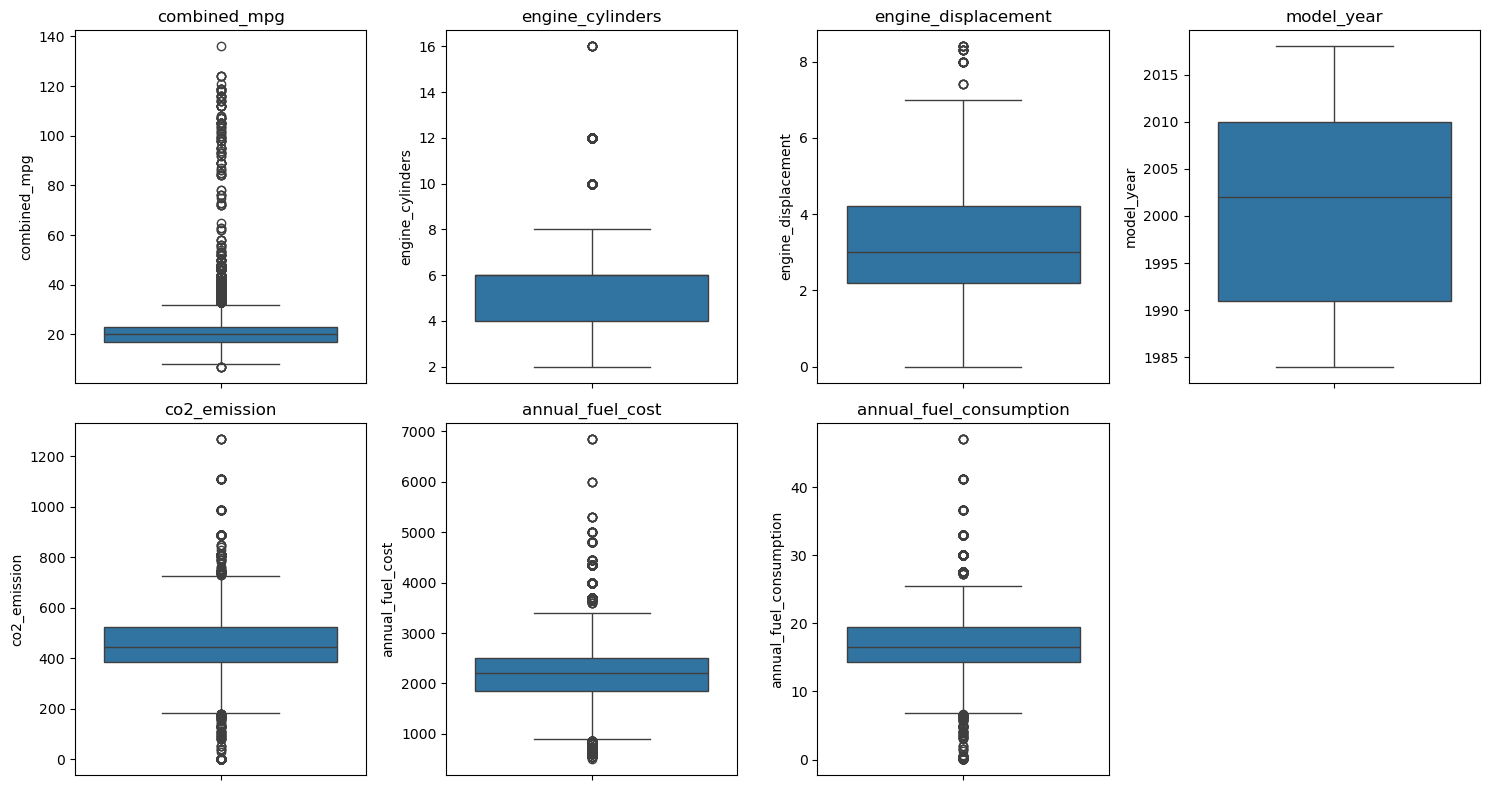

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15,8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2,4,i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

Boxplots were used to detect potential outliers in all numerical features.

Several numerical features contain extreme values; however, these values correspond to genuine vehicle characteristics rather than data entry errors.

Examples include:

- High combined MPG for electric and hybrid vehicles.
- Large engine displacement for trucks and high-performance cars.
- Higher fuel cost and fuel consumption for heavy vehicles.
- Zero CO₂ emissions for electric vehicles.

Since these observations represent valid real-world vehicles, the outliers were retained. Removing them could reduce the model's ability to generalize across different vehicle types.

#### Step 6: EDA

##### Distribution of Target Variable (combined_mpg)

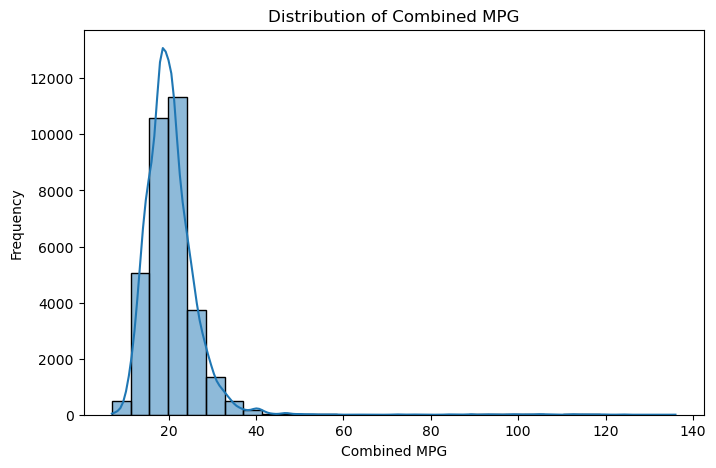

In [33]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="combined_mpg",
    bins=30,
    kde=True
)

plt.title("Distribution of Combined MPG")
plt.xlabel("Combined MPG")
plt.ylabel("Frequency")

plt.show()

The distribution of the target variable (`combined_mpg`) is **positively skewed (right-skewed)**.

Key observations:

- Most vehicles have a combined fuel economy between **15 and 25 MPG**.
- The highest concentration of vehicles lies around **20 MPG**.
- A small number of vehicles have exceptionally high fuel economy, creating a long right tail.
- These high MPG values are expected for electric and hybrid vehicles and therefore represent valid observations rather than data errors.



##### Distribution of Engine Displacement

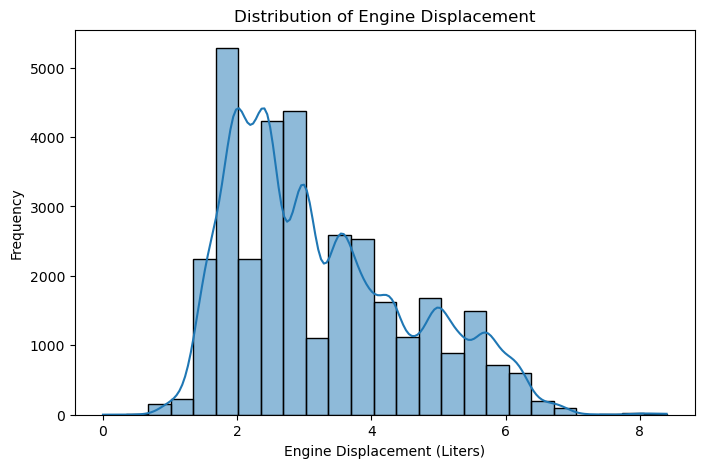

In [34]:
plt.figure(figsize=(8,5))

sns.histplot(df["engine_displacement"], bins=25, kde=True)

plt.title("Distribution of Engine Displacement")
plt.xlabel("Engine Displacement (Liters)")
plt.ylabel("Frequency")

plt.show()

The distribution of **Engine Displacement** is **positively skewed (right-skewed)**.

Key observations:

- Most vehicles have an engine displacement between **1.5 and 3.5 liters**.
- Engine sizes between **2 and 3 liters** are the most common.
- A small number of vehicles have very large engines (above **6 liters**), creating a right tail.
- These larger engines are expected in sports cars, luxury vehicles, and heavy-duty trucks.

The distribution reflects a realistic mix of small, medium, and high-performance vehicles.

##### Countplot of Engine Cylinders

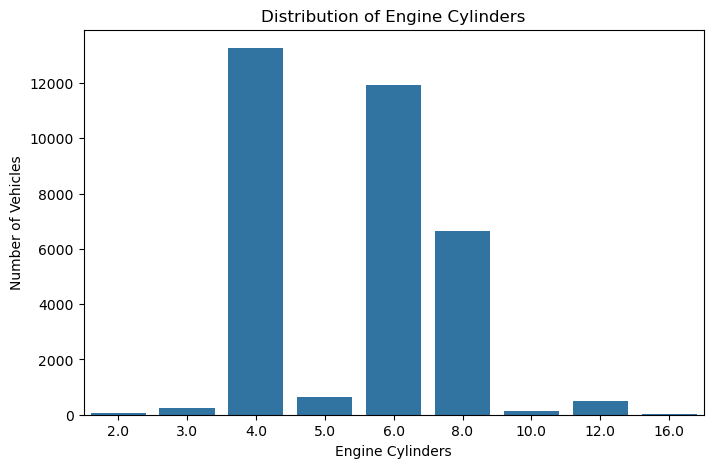

In [35]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="engine_cylinders")

plt.title("Distribution of Engine Cylinders")
plt.xlabel("Engine Cylinders")
plt.ylabel("Number of Vehicles")

plt.show()

The count plot shows the distribution of vehicles based on the number of engine cylinders.

Key observations:

- **4-cylinder engines** are the most common in the dataset.
- **6-cylinder engines** are the second most common.
- **8-cylinder engines** are also well represented but less frequent.
- Vehicles with **2, 3, 5, 10, 12, and 16 cylinders** are relatively rare.

The distribution indicates that most vehicles are equipped with **4- or 6-cylinder engines**, reflecting the industry's focus on balancing performance and fuel efficiency.

#### Fuel Type Distribution

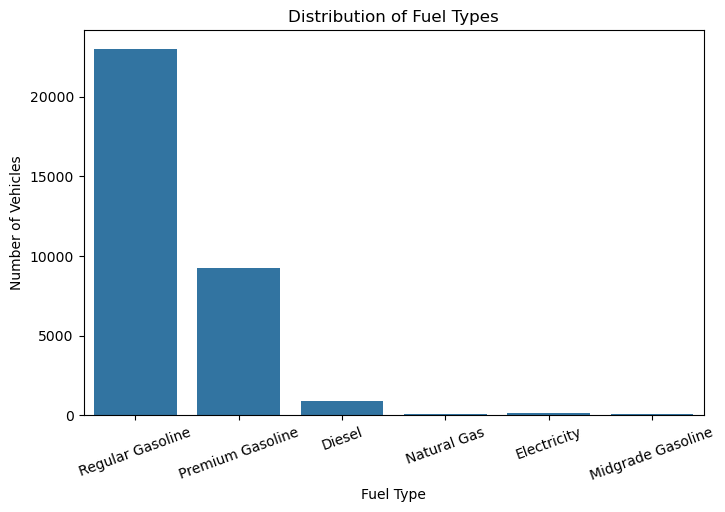

In [36]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="fuel_type")

plt.title("Distribution of Fuel Types")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Vehicles")

plt.xticks(rotation=20)

plt.show()

The count plot shows the distribution of different fuel types in the dataset.

Key observations:

- **Regular Gasoline** is the most commonly used fuel type.
- **Premium Gasoline** is the second most common.
- **Diesel** vehicles represent a much smaller portion of the dataset.
- **Electricity**, **Natural Gas**, and **Midgrade Gasoline** are present in very small numbers.

The dataset is heavily dominated by gasoline-powered vehicles, while alternative fuel vehicles are comparatively rare.

#### Vehicle Class Distribution

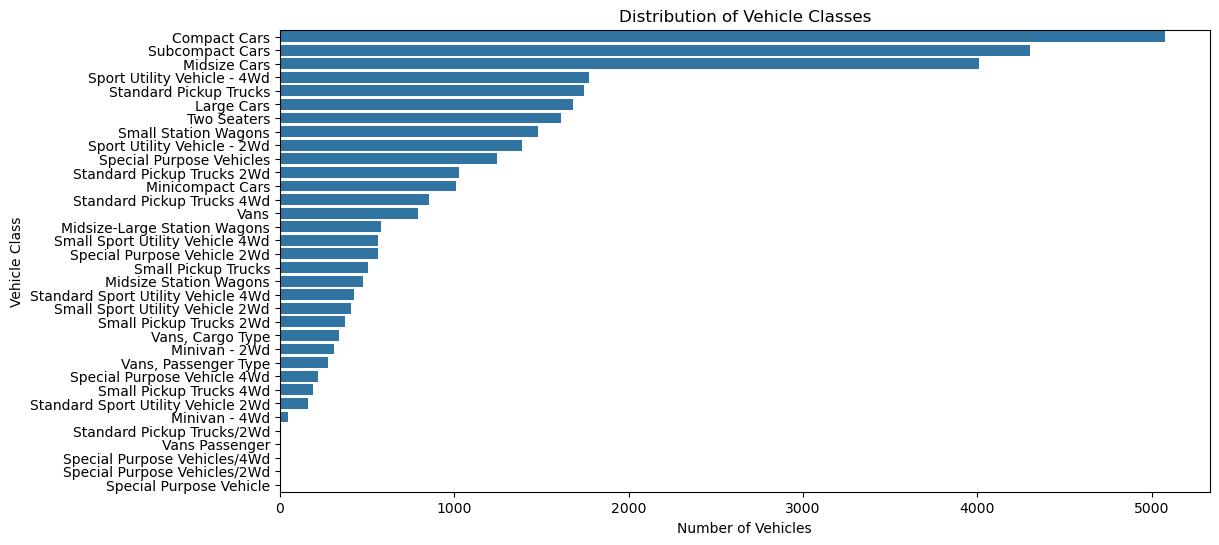

In [37]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    y="vehicle_class",
    order=df["vehicle_class"].value_counts().index
)

plt.title("Distribution of Vehicle Classes")
plt.xlabel("Number of Vehicles")
plt.ylabel("Vehicle Class")

plt.show()

The count plot shows the distribution of different vehicle classes in the dataset.

Key observations:

- **Compact Cars** are the most common vehicle class.
- **Subcompact Cars** and **Midsize Cars** are also well represented.
- **Pickup Trucks** and **Sport Utility Vehicles (SUVs)** have a significant presence.
- Specialized vehicle classes such as **Minivans**, **Cargo Vans**, and **Special Purpose Vehicles** appear less frequently.

The dataset contains a diverse range of vehicle classes, making it suitable for building a robust regression model.

#### Distribution of Drive Types

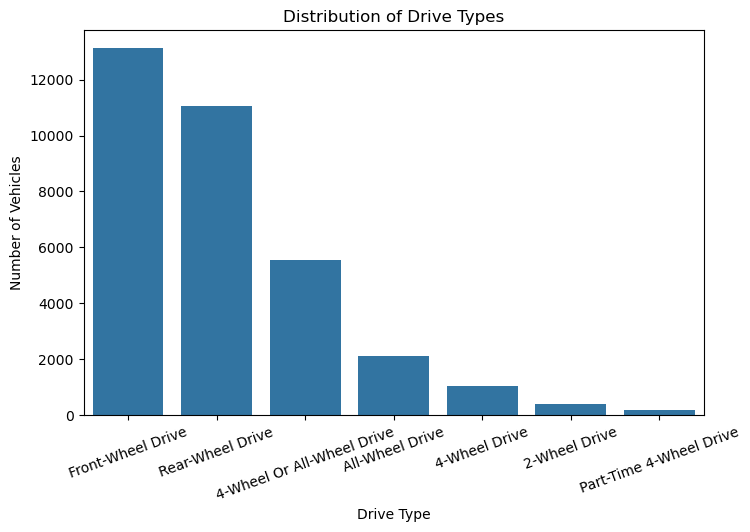

In [38]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="drive_type",
    order=df["drive_type"].value_counts().index
)

plt.title("Distribution of Drive Types")
plt.xlabel("Drive Type")
plt.ylabel("Number of Vehicles")

plt.xticks(rotation=20)

plt.show()

The count plot illustrates the distribution of different drive types in the dataset.

Key observations:

- **Front-Wheel Drive (FWD)** is the most common drive system.
- **Rear-Wheel Drive (RWD)** is the second most common.
- **4-Wheel or All-Wheel Drive** vehicles are also well represented.
- **All-Wheel Drive (AWD)** and **4-Wheel Drive (4WD)** appear less frequently.
- **2-Wheel Drive** and **Part-Time 4-Wheel Drive** are the least common drive types.

Overall, the dataset is dominated by Front-Wheel Drive and Rear-Wheel Drive vehicles.

#### Top 15 Manufacturers

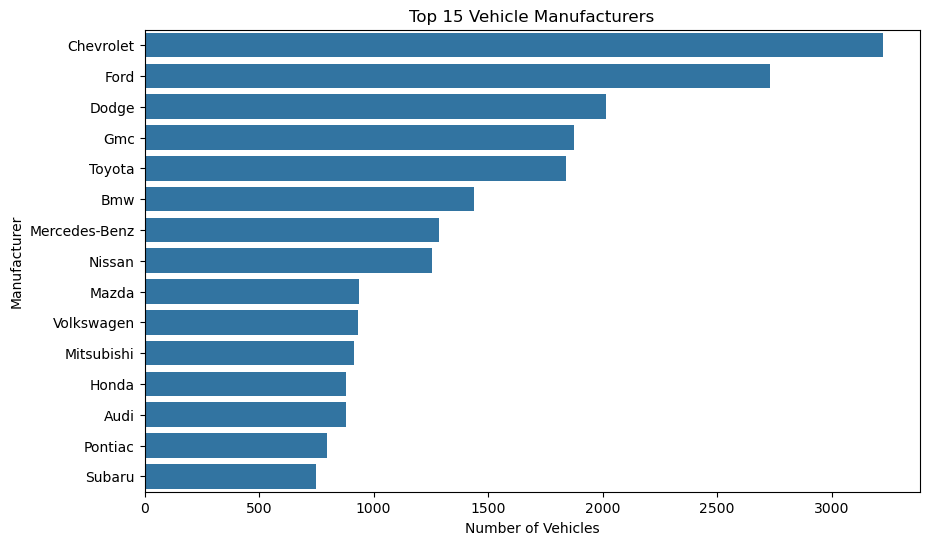

In [39]:
# Top 15 manufacturers
top15 = df["manufacturer"].value_counts().head(15)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top15.values,
    y=top15.index
)

plt.title("Top 15 Vehicle Manufacturers")
plt.xlabel("Number of Vehicles")
plt.ylabel("Manufacturer")

plt.show()

The chart displays the top 15 vehicle manufacturers based on the number of vehicles in the dataset.

Key observations:

- **Chevrolet** has the highest number of vehicles in the dataset.
- **Ford** is the second most represented manufacturer.
- **Dodge**, **GMC**, and **Toyota** also contribute a significant number of vehicles.
- Manufacturers such as **Audi**, **Honda**, **Porsche**, and **Pontiac** have comparatively fewer records among the top 15.

The dataset contains vehicles from a wide range of manufacturers, making it suitable for building a generalized machine learning model.

#### Engine Displacement vs Combined MPG

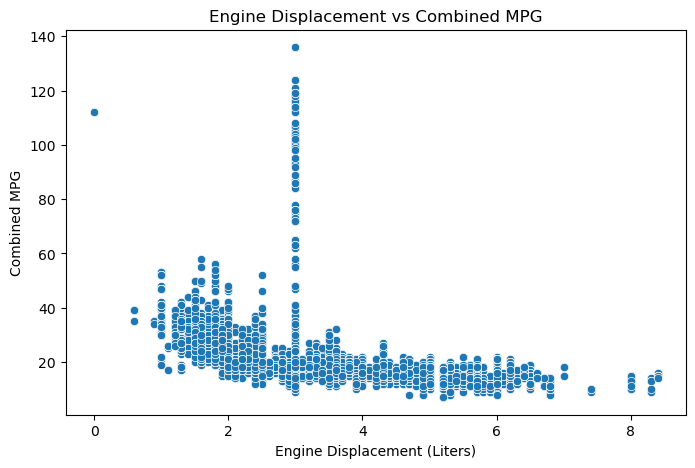

In [40]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="engine_displacement",
    y="combined_mpg"
)

plt.title("Engine Displacement vs Combined MPG")
plt.xlabel("Engine Displacement (Liters)")
plt.ylabel("Combined MPG")

plt.show()

The scatter plot shows the relationship between **Engine Displacement** and **Combined MPG**.

Key observations:

- There is a **clear negative relationship** between engine displacement and combined fuel economy.
- Vehicles with **smaller engines (approximately 1–3 liters)** generally achieve higher MPG.
- As engine displacement increases, fuel efficiency decreases.
- Vehicles with engine sizes above **5 liters** mostly have lower MPG values.
- A few vehicles with very high MPG are likely electric or hybrid vehicles, which appear as valid extreme observations.

#### Engine Cylinders vs Combined MPG

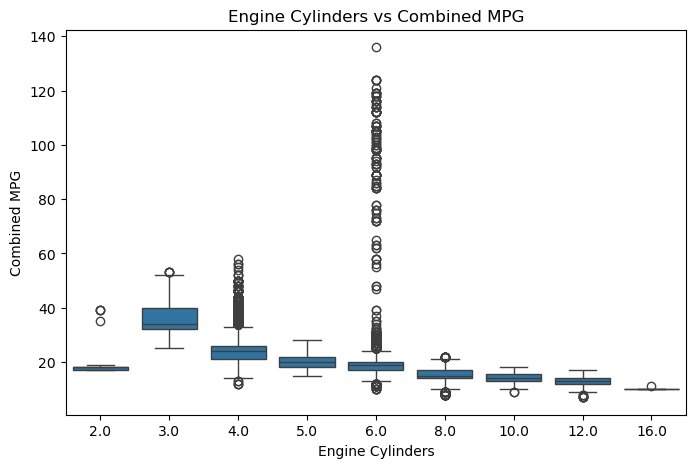

In [41]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="engine_cylinders",
    y="combined_mpg"
)

plt.title("Engine Cylinders vs Combined MPG")
plt.xlabel("Engine Cylinders")
plt.ylabel("Combined MPG")

plt.show()

The box plot compares the distribution of **Combined MPG** across different engine cylinder configurations.

Key observations:

- Vehicles with **3 and 4 cylinders** generally achieve higher fuel efficiency.
- As the number of cylinders increases, the median combined MPG decreases.
- Vehicles with **8, 10, 12, and 16 cylinders** have the lowest fuel economy.
- The **6-cylinder** category shows a wider spread because it includes conventional, hybrid, and performance vehicles.

Overall, the chart indicates a negative relationship between the number of engine cylinders and fuel efficiency.

#### Model Year vs Combined MPG

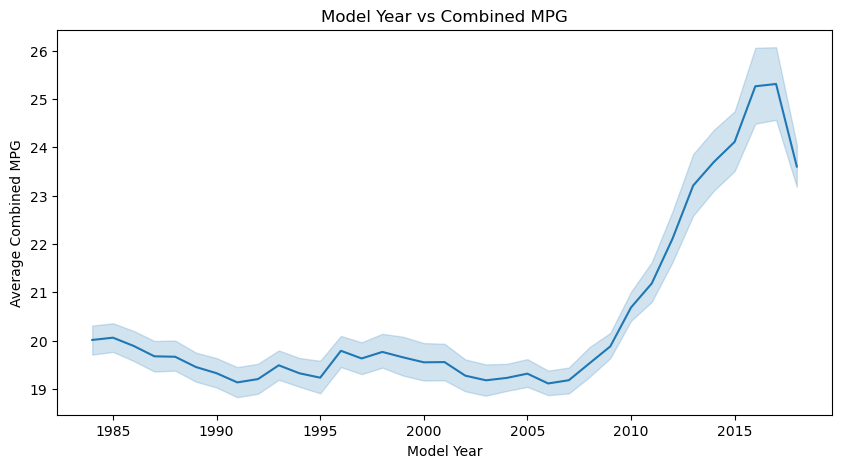

In [42]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data=df,
    x="model_year",
    y="combined_mpg"
)

plt.title("Model Year vs Combined MPG")
plt.xlabel("Model Year")
plt.ylabel("Average Combined MPG")

plt.show()

The line plot illustrates the trend of average combined fuel economy across different model years.

Key observations:

- From **1984 to around 2008**, the average combined MPG remained relatively stable, with only minor fluctuations.
- From **2009 onwards**, there is a noticeable increase in average fuel efficiency.
- The highest average MPG is observed around **2016–2017**.
- A slight decline is visible in **2018**, but the average fuel economy remains much higher than in earlier years.

Overall, the trend indicates that newer vehicles are generally more fuel-efficient than older models.

#### Fuel Type vs Combined MPG

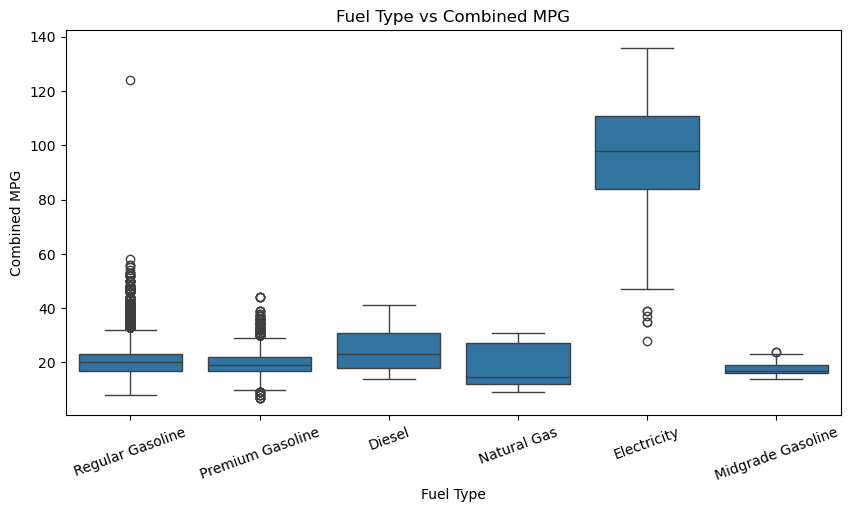

In [43]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x="fuel_type",
    y="combined_mpg"
)

plt.title("Fuel Type vs Combined MPG")
plt.xlabel("Fuel Type")
plt.ylabel("Combined MPG")

plt.xticks(rotation=20)

plt.show()

The box plot compares the distribution of **Combined MPG** across different fuel types.

Key observations:

- **Electric vehicles** have the highest combined MPG by a large margin.
- **Diesel** vehicles generally achieve better fuel efficiency than gasoline-powered vehicles.
- **Regular**, **Premium**, and **Midgrade Gasoline** vehicles have similar median MPG values.
- **Natural Gas** vehicles show greater variation in fuel efficiency.
- Electric vehicles exhibit the widest MPG range because their fuel economy is measured using **MPGe (Miles Per Gallon equivalent)**.

Overall, fuel type has a significant influence on vehicle fuel efficiency.

#### Vehicle Class vs Combined MPG

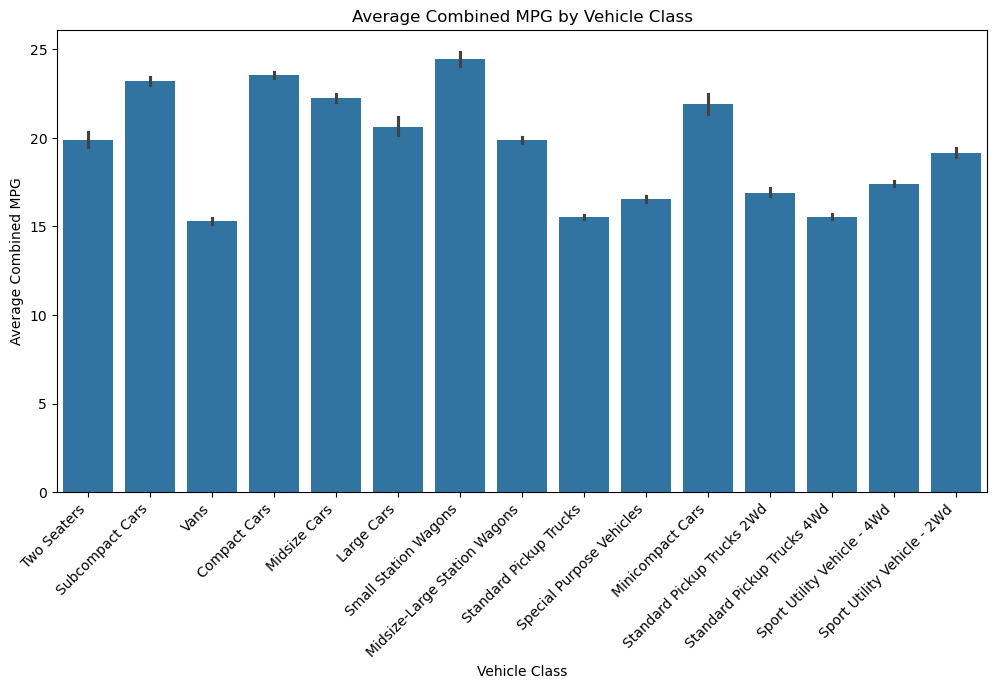

In [44]:

top15 = df["vehicle_class"].value_counts().head(15).index

plt.figure(figsize=(12,6))

sns.barplot(
    data=df[df["vehicle_class"].isin(top15)],
    x="vehicle_class",
    y="combined_mpg",
    estimator="mean"
)

plt.xticks(rotation=45, ha="right")

plt.title("Average Combined MPG by Vehicle Class")
plt.xlabel("Vehicle Class")
plt.ylabel("Average Combined MPG")

plt.show()

The bar chart compares the **average combined fuel economy (MPG)** across the top 15 vehicle classes.

Key observations:

- **Small Station Wagons** have the highest average combined MPG among the selected vehicle classes.
- **Compact Cars** and **Subcompact Cars** also achieve high average fuel efficiency.
- **Midsize Cars** and **Minicompact Cars** provide moderate to high fuel economy.
- **Standard Pickup Trucks**, **Special Purpose Vehicles**, and **4WD Pickup Trucks** have the lowest average MPG.

Overall, smaller passenger vehicles tend to be more fuel-efficient than larger utility vehicles and pickup trucks.

#### Average Combined MPG by Drive Type

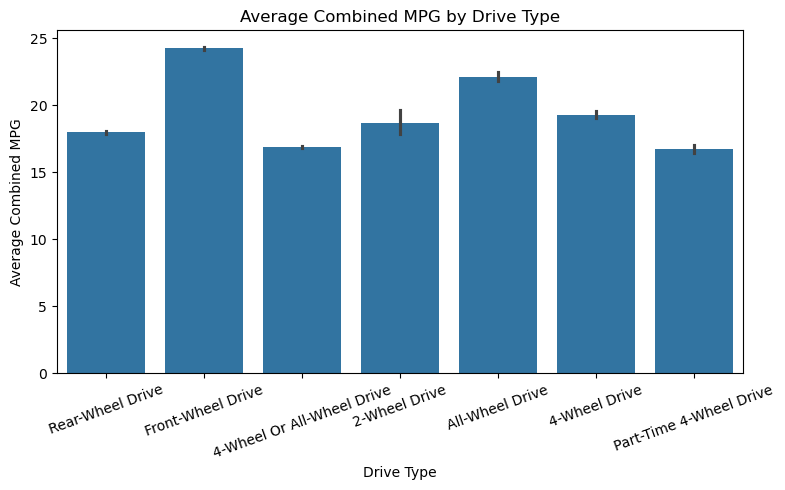

In [45]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=df,
    x="drive_type",
    y="combined_mpg"
)

plt.title("Average Combined MPG by Drive Type")
plt.xlabel("Drive Type")
plt.ylabel("Average Combined MPG")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

The bar chart compares the average combined fuel economy (MPG) across different drive types.

Key observations:

- **Front-Wheel Drive (FWD)** vehicles have the highest average combined MPG.
- **All-Wheel Drive (AWD)** vehicles also show relatively good fuel efficiency.
- **Rear-Wheel Drive (RWD)** vehicles have moderate fuel economy.
- **4-Wheel Drive**, **4-Wheel or All-Wheel Drive**, and **Part-Time 4-Wheel Drive** vehicles have lower average MPG.

Overall, drive type influences fuel efficiency, with simpler drivetrain systems generally providing better fuel economy.

#### CO₂ Emission vs Combined MPG

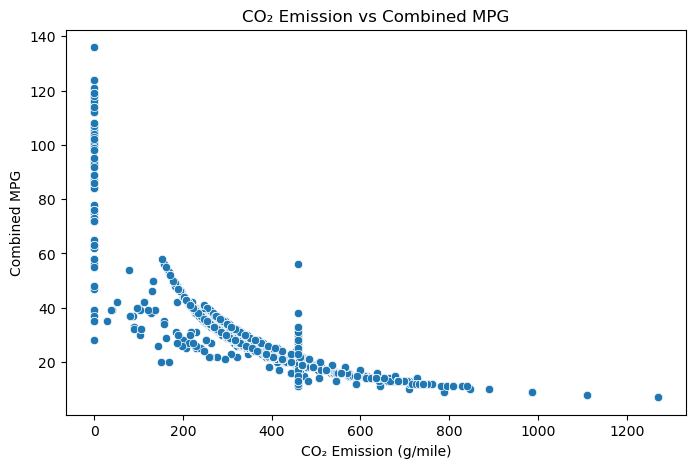

In [46]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="co2_emission",
    y="combined_mpg"
)

plt.title("CO₂ Emission vs Combined MPG")
plt.xlabel("CO₂ Emission (g/mile)")
plt.ylabel("Combined MPG")

plt.show()

The scatter plot illustrates the relationship between **CO₂ Emission** and **Combined MPG**.

Key observations:

- There is a **strong negative relationship** between CO₂ emission and combined fuel economy.
- Vehicles with **low CO₂ emissions** generally achieve high MPG.
- As CO₂ emissions increase, the combined MPG decreases significantly.
- High-emission vehicles (above 600 g/mile) mostly have fuel economy below 20 MPG.
- A few vehicles with extremely low CO₂ emissions and very high MPG are likely electric or hybrid vehicles.

Overall, the plot confirms that vehicles producing more CO₂ are generally less fuel-efficient.

#### Annual Fuel Cost vs Combined MPG

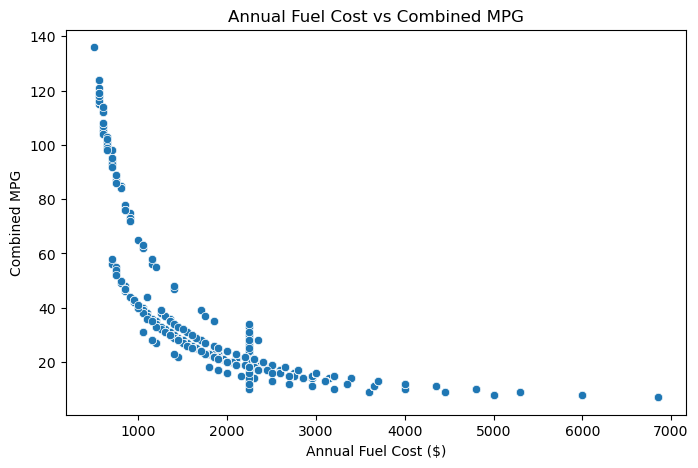

In [47]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="annual_fuel_cost",
    y="combined_mpg"
)

plt.title("Annual Fuel Cost vs Combined MPG")
plt.xlabel("Annual Fuel Cost ($)")
plt.ylabel("Combined MPG")

plt.show()

The scatter plot illustrates the relationship between **Annual Fuel Cost** and **Combined MPG**.

Key observations:

- There is a **strong negative relationship** between annual fuel cost and combined MPG.
- Vehicles with **lower annual fuel costs** generally achieve higher fuel efficiency.
- As annual fuel cost increases, the combined MPG decreases.
- Vehicles with annual fuel costs above **$4,000** mostly have fuel economy below **15 MPG**.
- A few vehicles with very low fuel costs and exceptionally high MPG are likely electric or hybrid vehicles.

Overall, the chart shows that fuel-efficient vehicles are less expensive to operate annually.

#### Annual Fuel Consumption vs Combined MPG

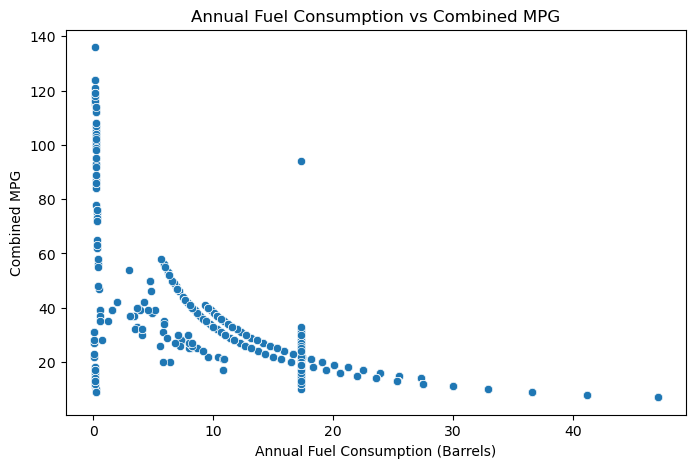

In [48]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="annual_fuel_consumption",
    y="combined_mpg"
)

plt.title("Annual Fuel Consumption vs Combined MPG")
plt.xlabel("Annual Fuel Consumption (Barrels)")
plt.ylabel("Combined MPG")

plt.show()

The scatter plot shows the relationship between **Annual Fuel Consumption** and **Combined MPG**.

Key observations:

- There is a **strong negative relationship** between annual fuel consumption and combined MPG.
- Vehicles with **lower annual fuel consumption** generally achieve much higher fuel efficiency.
- As annual fuel consumption increases, the combined MPG decreases steadily.
- Vehicles consuming more than **25 barrels of fuel per year** mostly have fuel economy below **15 MPG**.
- A few vehicles with extremely low fuel consumption and very high MPG are likely hybrid or electric vehicles.

Overall, vehicles that consume less fuel annually are significantly more fuel-efficient.

#### Correlation Heatmap

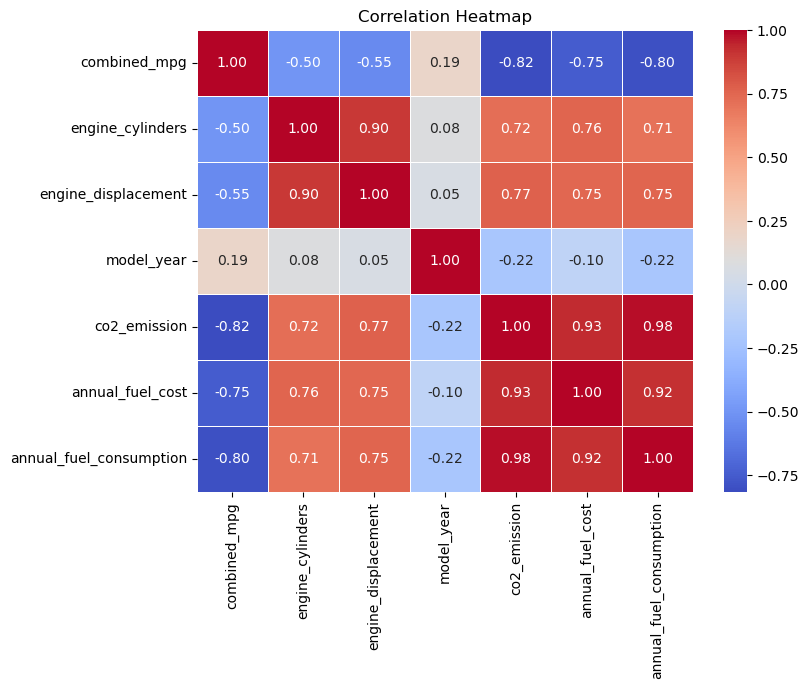

In [49]:
# Select only numerical columns
numerical_df = df.select_dtypes(include=["int64", "float64"])

# Correlation matrix
corr = numerical_df.corr()

# Plot Heatmap
plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.show()

The correlation heatmap illustrates the strength and direction of relationships between all numerical variables.

##### Relationship with the Target Variable (Combined MPG)

| Feature | Correlation | Interpretation |
|---------|------------:|----------------|
| CO₂ Emission | **-0.82** | Strong Negative |
| Annual Fuel Consumption | **-0.80** | Strong Negative |
| Annual Fuel Cost | **-0.75** | Strong Negative |
| Engine Displacement | **-0.56** | Moderate Negative |
| Engine Cylinders | **-0.51** | Moderate Negative |
| Model Year | **0.19** | Weak Positive |

Key observations:

- **CO₂ Emission** has the strongest negative correlation with Combined MPG.
- Vehicles with higher **annual fuel consumption** generally have lower fuel efficiency.
- Vehicles with larger **engine displacement** and more **engine cylinders** tend to have lower MPG.
- **Model Year** has a weak positive correlation, suggesting that newer vehicles are generally more fuel-efficient.

The heatmap also reveals strong correlations among some predictor variables, indicating the presence of multicollinearity.

#### Pairplot

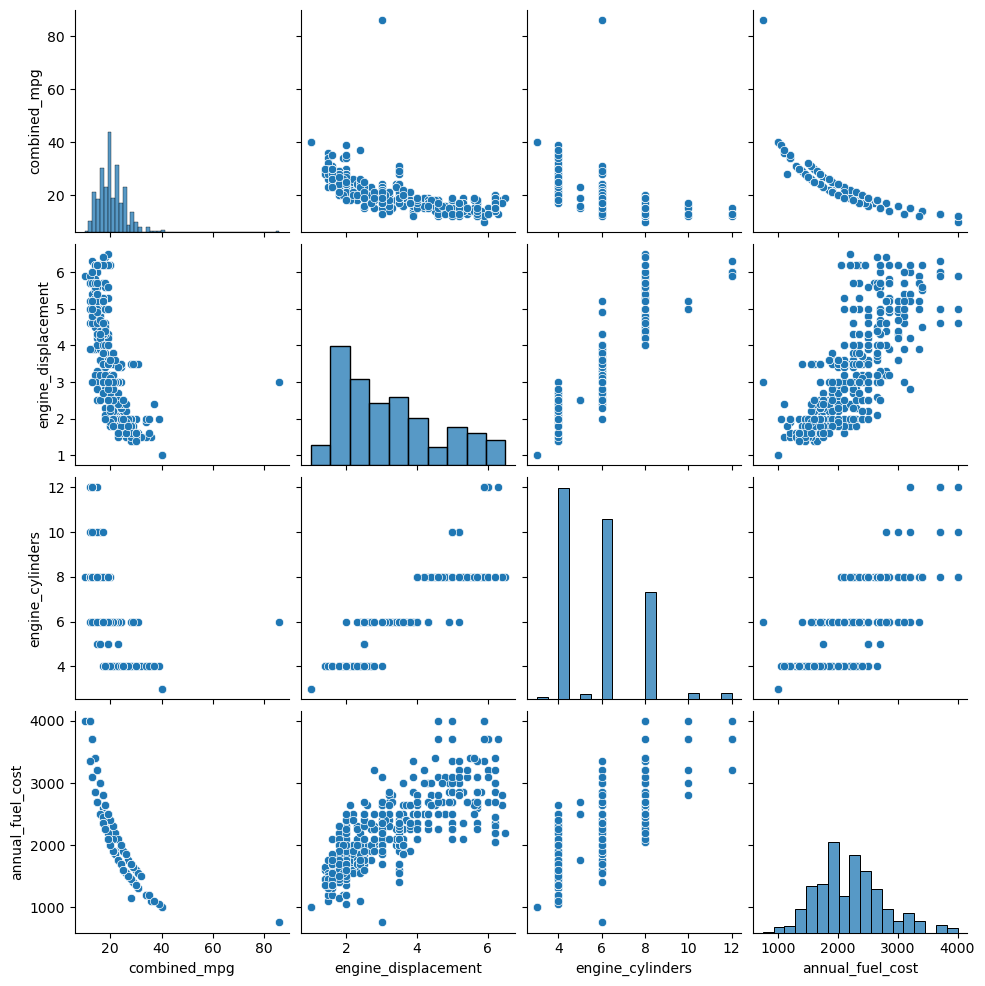

In [50]:
sample_df = df[
    [
        "combined_mpg",
        "engine_displacement",
        "engine_cylinders",
        #"co2_emission",
        "annual_fuel_cost"
    ]
].sample(500, random_state=42)

sns.pairplot(sample_df)

plt.show()

#### Step 7:Encoding

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [52]:
categorical_features = [
    "drive_type",
    "transmission",
    "fuel_type",
    "vehicle_class",
    "manufacturer"
]

numerical_features = [
    "engine_cylinders",
    "engine_displacement",
    "model_year",
    "co2_emission",
    "annual_fuel_cost",
    "annual_fuel_consumption"
]

In [53]:
# create the transformer

In [54]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

#### Step 8: Model Developement

In [55]:
x = df.drop("combined_mpg", axis=1)
# Input variable
x

,engine_cylinders,engine_displacement,model_year,drive_type,transmission,fuel_type,vehicle_class,manufacturer,co2_emission,annual_fuel_cost,annual_fuel_consumption
0,4.0,2.0,1985,Rear-Wheel Drive,Manual 5-Spd,Regular Gasoline,Two Seaters,Alfa Romeo,423.190476,1900.0,15.695714
1,12.0,4.9,1985,Rear-Wheel Drive,Manual 5-Spd,Regular Gasoline,Two Seaters,Ferrari,807.909091,3650.0,29.964545
2,4.0,2.2,1985,Front-Wheel Drive,Manual 5-Spd,Regular Gasoline,Subcompact Cars,Dodge,329.148148,1500.0,12.207778
3,8.0,5.2,1985,Rear-Wheel Drive,Automatic 3-Spd,Regular Gasoline,Vans,Dodge,807.909091,3650.0,29.964545
4,4.0,2.2,1993,4-Wheel Or All-Wheel Drive,Manual 5-Spd,Premium Gasoline,Compact Cars,Subaru,467.736842,2500.0,17.347895
...,...,...,...,...,...,...,...,...,...,...,...
39099,4.0,2.2,1993,4-Wheel Or All-Wheel Drive,Manual 5-Spd,Regular Gasoline,Compact Cars,Subaru,423.190476,1900.0,15.695714
39100,4.0,2.2,1993,4-Wheel Or All-Wheel Drive,Automatic 4-Spd,Premium Gasoline,Compact Cars,Subaru,493.722222,2650.0,18.311667
39111,6.0,4.0,1989,4-Wheel Or All-Wheel Drive,Automatic 4-Spd,Regular Gasoline,Special Purpose Vehicles,Chevrolet,555.437500,2500.0,20.600625
39134,4.0,1.6,2014,Front-Wheel Drive,Manual 6-Spd,Regular Gasoline,Large Cars,Kia,368.000000,1700.0,17.347895


In [56]:
y=df["combined_mpg"]            # Target varible
y

0        21
1        11
2        27
3        11
4        19
         ..
39099    21
39100    18
39111    16
39134    24
39170    11
Name: combined_mpg, Length: 33434, dtype: int64

In [57]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error

In [58]:
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

In [59]:
x_train_processed = preprocessor.fit_transform(x_train)

x_test_processed = preprocessor.transform(x_test)

#### LinearRegression

In [60]:
from sklearn.linear_model import LinearRegression

#### LinearRegression

In [61]:
lr= LinearRegression()

In [62]:
lr.fit(x_train_processed,y_train)

LinearRegression()

In [63]:
y_pred=lr.predict(x_test_processed) 

In [64]:
LR_r2score= r2_score(y_test,y_pred)
print("Linear R2_score:",LR_r2score)

LR_MSE=mean_squared_error(y_test,y_pred)
print("Linear MSE:",LR_MSE)

LR_RMSE=root_mean_squared_error(y_test,y_pred)
print("Linear RMSE:", LR_RMSE)

LR_MAE=mean_absolute_error(y_test,y_pred)
print("Linear MAE:",LR_MAE)

LR_MAPE=mean_absolute_percentage_error(y_test,y_pred)
print("Linear MAPE",LR_MAPE)

Linear R2_score: 0.9290117849393715
Linear MSE: 2.925602549148043
Linear RMSE: 1.710439285431682
Linear MAE: 1.0344739053812704
Linear MAPE 0.05215142698081291


In [65]:
lr.score(x_train_processed,y_train)

0.9148655796402911

In [66]:
print("training Accuracy:", lr.score(x_train_processed, y_train))
print("testing Accuracy:", lr.score(x_test_processed, y_test))

training Accuracy: 0.9148655796402911
testing Accuracy: 0.9290117849393715


In [67]:
#Check on real data

In [68]:
new_data = pd.DataFrame({
    "engine_cylinders": [4],
    "engine_displacement": [2.0],
    "model_year": [2022],
    "drive_type": ["Front-Wheel Drive"],
    "transmission": ["Automatic 6-Spd"],
    "fuel_type": ["Regular Gasoline"],
    "vehicle_class": ["Compact Cars"],
    "manufacturer": ["Toyota"],
    "co2_emission": [220],
    "annual_fuel_cost": [1800],
    "annual_fuel_consumption": [8.2]
})

In [69]:
new_processed = preprocessor.transform(new_data)
prediction = lr.predict(new_processed)
print("Prediction l2 on MPG:",prediction)

Prediction l2 on MPG: [27.2857905]


In [70]:
# to see order of columns in training -- print(x_train.columns.tolist())

In [71]:
from sklearn.linear_model import Lasso, Ridge, ElasticNet

#### Lasso

In [72]:
l1=Lasso()

In [73]:
l1.fit(x_train_processed,y_train)

Lasso()

In [74]:
y_predl1=l1.predict(x_test_processed)

In [75]:
L1_r2score= r2_score(y_test,y_predl1)
print("L1 R2_score:",L1_r2score)

L1_MSE=mean_squared_error(y_test,y_predl1)
print("L1 MSE:",L1_MSE)

L1_RMSE=root_mean_squared_error(y_test,y_predl1)
print("L1 RMSE:", L1_RMSE)

L1_MAE=mean_absolute_error(y_test,y_predl1)
print("L1 MAE:",L1_MAE)

L1_MAPE=mean_absolute_percentage_error(y_test,y_predl1)
print("L1:",L1_MAPE)

L1 R2_score: 0.6947152184874905
L1 MSE: 12.581552223088021
L1 RMSE: 3.5470483818363716
L1 MAE: 1.4943129071636714
L1: 0.07036618881330982


In [76]:
#Prediction on new data

In [77]:
new_data = pd.DataFrame({
    "engine_cylinders": [4],
    "engine_displacement": [2.0],
    "model_year": [2022],
    "drive_type": ["Front-Wheel Drive"],
    "transmission": ["Automatic 6-Spd"],
    "fuel_type": ["Regular Gasoline"],
    "vehicle_class": ["Compact Cars"],
    "manufacturer": ["Toyota"],
    "co2_emission": [220],
    "annual_fuel_cost": [1800],
    "annual_fuel_consumption": [8.2]
})

In [78]:
new_processed = preprocessor.transform(new_data)
prediction = l1.predict(new_processed)
print("Prediction l2 on MPG:",prediction)

Prediction l2 on MPG: [30.29397005]


#### Ridge

In [79]:
l2=Ridge()

#### Ridge

In [80]:
l2.fit(x_train_processed, (y_train))

Ridge()

In [81]:
y_predl2=l2.predict(x_test_processed)


In [82]:
L2_r2score= r2_score(y_test,y_predl2)
print("L2 R2_score:",L2_r2score)

L2_MSE=mean_squared_error(y_test,y_predl2)
print("L2 MSE:",L2_MSE)

L2_RMSE=root_mean_squared_error(y_test,y_predl2)
print("L2 RMSE:", L2_RMSE)

L2_MAE=mean_absolute_error(y_test,y_predl2)
print("L2 MAE:",L2_MAE)

L2_MAPE=mean_absolute_percentage_error(y_test,y_predl2)
print("L2 MAPE",L2_MAPE)

L2 R2_score: 0.9283923522751915
L2 MSE: 2.9511309242424595
L2 RMSE: 1.7178855969599545
L2 MAE: 1.0378232328324133
L2 MAPE 0.05243850827298


In [83]:
new_data = pd.DataFrame({
    "engine_cylinders": [4],
    "engine_displacement": [2.0],
    "model_year": [2022],
    "drive_type": ["Front-Wheel Drive"],
    "transmission": ["Automatic 6-Spd"],
    "fuel_type": ["Regular Gasoline"],
    "vehicle_class": ["Compact Cars"],
    "manufacturer": ["Toyota"],
    "co2_emission": [220],
    "annual_fuel_cost": [1800],
    "annual_fuel_consumption": [8.2]
})

In [84]:
new_processed = preprocessor.transform(new_data)
prediction = l2.predict(new_processed)
print("Prediction l2 on MPG:",prediction)

Prediction l2 on MPG: [27.19958244]


#### ElasticNet

In [85]:
l12=ElasticNet()

In [86]:
l12.fit(x_train_processed,y_train)

ElasticNet()

In [87]:
y_predl12=l12.predict(x_test_processed)

In [88]:
L12_r2score= r2_score(y_test,y_predl12)
print("L12 R2_score:",L12_r2score)

L12_MSE=mean_squared_error(y_test,y_predl12)
print("L12 MSE:",L12_MSE)

L12_RMSE=root_mean_squared_error(y_test,y_predl12)
print("L12 RMSE:", L12_RMSE)

L12_MAE=mean_absolute_error(y_test,y_predl12)
print("L12 MAE:",L12_MAE)

L12_MAPE=mean_absolute_percentage_error(y_test,y_predl12)
print("L12 MAPE",L12_MAPE)

L12 R2_score: 0.6683956339399557
L12 MSE: 13.66624837411847
L12 RMSE: 3.6967889274502097
L12 MAE: 1.5195453650523367
L12 MAPE 0.070350685015869


In [89]:
# Prediction on real data

In [90]:
new_data = pd.DataFrame({
    "engine_cylinders": [4],
    "engine_displacement": [2.0],
    "model_year": [2022],
    "drive_type": ["Front-Wheel Drive"],
    "transmission": ["Automatic 6-Spd"],
    "fuel_type": ["Regular Gasoline"],
    "vehicle_class": ["Compact Cars"],
    "manufacturer": ["Toyota"],
    "co2_emission": [220],
    "annual_fuel_cost": [1800],
    "annual_fuel_consumption": [8.2]
})

In [91]:
new_processed = preprocessor.transform(new_data)
prediction = l12.predict(new_processed)
print("Prediction l12 on MPG:",prediction)

Prediction l12 on MPG: [28.19904281]


#### Visualisations on models

##### Visual on R2 Score

Text(0, 0.5, 'R2_score')

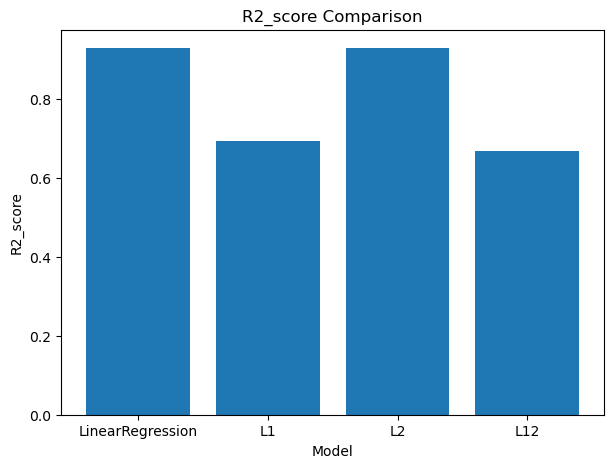

In [92]:
models=["LinearRegression","L1","L2","L12"]
R2_score= [LR_r2score, L1_r2score, L2_r2score, L12_r2score]
plt.figure(figsize=(7,5))
plt.bar(models,R2_score)
plt.title("R2_score Comparison")
plt.xlabel("Model")
plt.ylabel("R2_score")

#### Model Comparison Inference

##### R² Score Comparison

##### Inference
- Linear Regression achieved the highest R² score (~0.93), explaining most of the variance in the target variable.
- Ridge Regression achieved the second-highest R² score with only a small decrease in performance.
- Lasso and ElasticNet recorded lower R² scores due to stronger regularization.
- **Higher R² indicates better prediction performance.**

#### Visual on MSE

Text(0, 0.5, 'MSE')

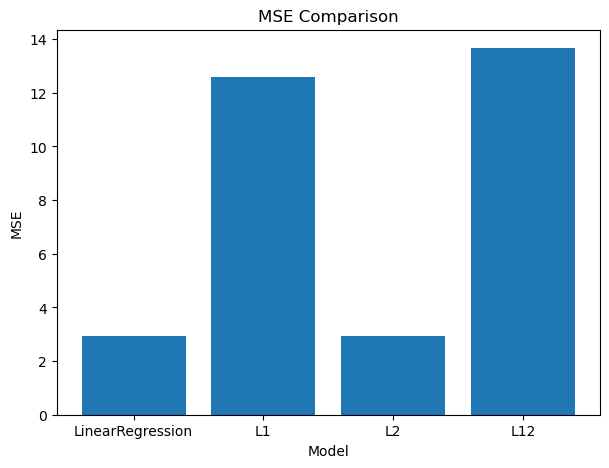

In [93]:
models=["LinearRegression","L1","L2","L12"]
R2_score= [LR_MSE, L1_MSE, L2_MSE, L12_MSE]
plt.figure(figsize=(7,5))
plt.bar(models,R2_score)
plt.title("MSE Comparison")
plt.xlabel("Model")
plt.ylabel("MSE")

#### MSE Comparison Inference

##### MSE Comparison

##### Inference
- Linear Regression produced the lowest Mean Squared Error (MSE), indicating the smallest squared prediction errors.
- Ridge Regression had the second-lowest MSE.
- Lasso and ElasticNet showed higher MSE values, resulting in larger prediction errors.
- **Lower MSE indicates better model performance.**

#### Visual on RMSE

Text(0, 0.5, 'RMSE')

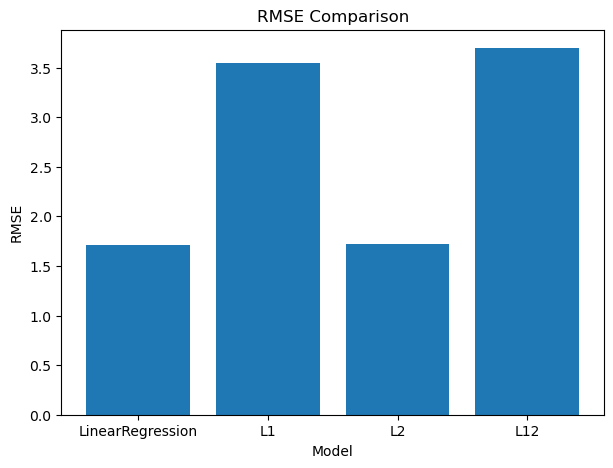

In [94]:
models=["LinearRegression","L1","L2","L12"]
R2_score= [LR_RMSE, L1_RMSE, L2_RMSE, L12_RMSE]
plt.figure(figsize=(7,5))
plt.bar(models,R2_score)
plt.title("RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")

#### RMSE Comparison Inference
##### RMSE Comparison

##### Inference
- Linear Regression achieved the lowest RMSE, showing the smallest average prediction error.
- Ridge Regression performed slightly worse than Linear Regression.
- Lasso and ElasticNet produced higher RMSE values.
- **Lower RMSE indicates more accurate predictions.**

#### Visual on MAE

Text(0, 0.5, 'MAE')

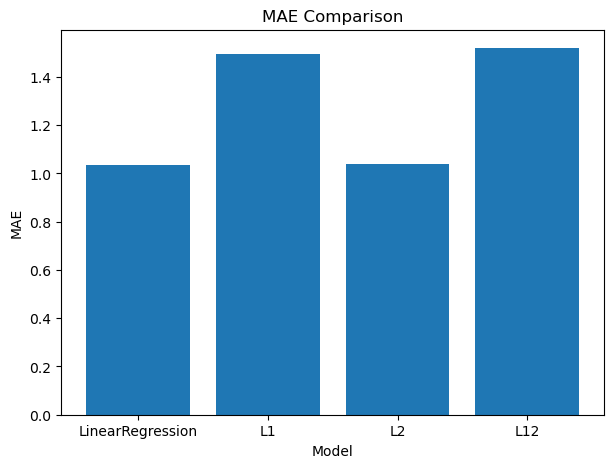

In [95]:
models=["LinearRegression","L1","L2","L12"]
R2_score= [LR_MAE, L1_MAE, L2_MAE, L12_MAE]
plt.figure(figsize=(7,5))
plt.bar(models,R2_score)
plt.title("MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE")

#### MAE Comparison Inferenc
##### MAE Comparison

### Inference
- Linear Regression achieved the lowest Mean Absolute Error (MAE).
- Ridge Regression had the second-lowest MAE.
- Lasso and ElasticNet showed larger average prediction errors.
- **Lower MAE indicates better prediction accuracy.**

#### Visual MAPE

Text(0, 0.5, 'MAPE')

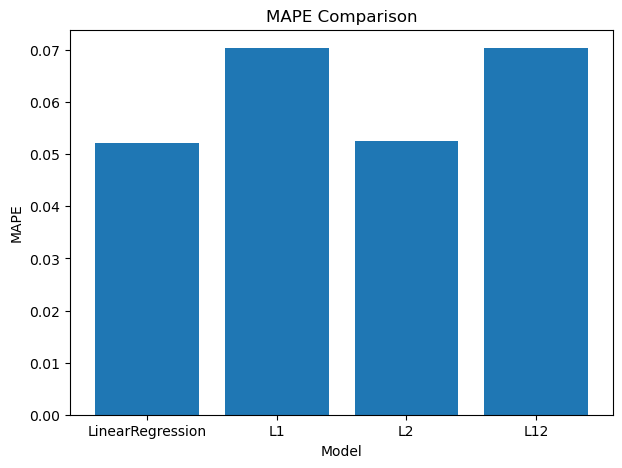

In [96]:
models=["LinearRegression","L1","L2","L12"]
R2_score= [LR_MAPE, L1_MAPE, L2_MAPE, L12_MAPE]
plt.figure(figsize=(7,5))
plt.bar(models,R2_score)
plt.title("MAPE Comparison")
plt.xlabel("Model")
plt.ylabel("MAPE")

#### MAPE Comparison Inference

##### MAPE Comparison

##### Inference
- Linear Regression achieved the lowest Mean Absolute Percentage Error (MAPE).
- Ridge Regression showed slightly higher percentage error.
- Lasso and ElasticNet had the highest percentage prediction errors.
- **Lower MAPE indicates more accurate percentage-based predictions.**

#### Actual vs Predicted

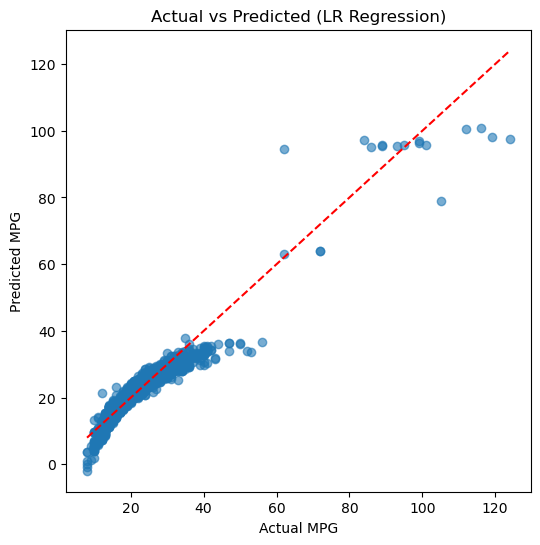

In [97]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linestyle='--')

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted (LR Regression)")
plt.show()

##### Linear Regression
- Most predictions are close to the ideal (red) line.
- The model predicts low and medium MPG vehicles accurately.
- A few high-MPG vehicles show larger prediction errors.
- Overall, the model provides a good fit to the data.

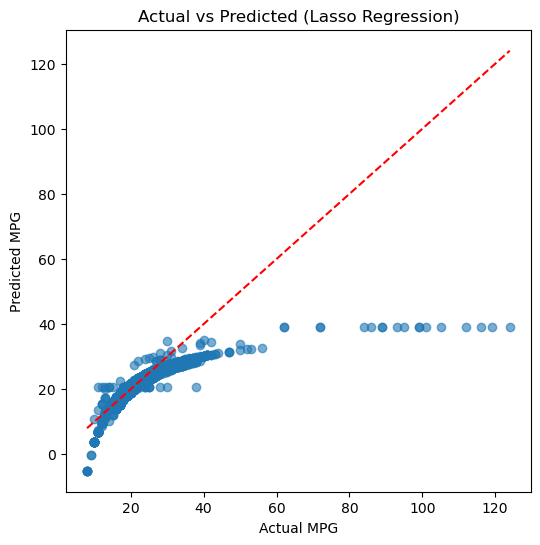

In [98]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_predl1, alpha=0.6)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linestyle='--')

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted (Lasso Regression)")
plt.show()

##### Lasso Regression (L1)
- The model predicts low and medium MPG reasonably well.
- High-MPG vehicles are consistently under-predicted.
- More points are away from the ideal line compared to Linear Regression.
- Overall, Lasso shows lower prediction accuracy due to coefficient shrinkage.

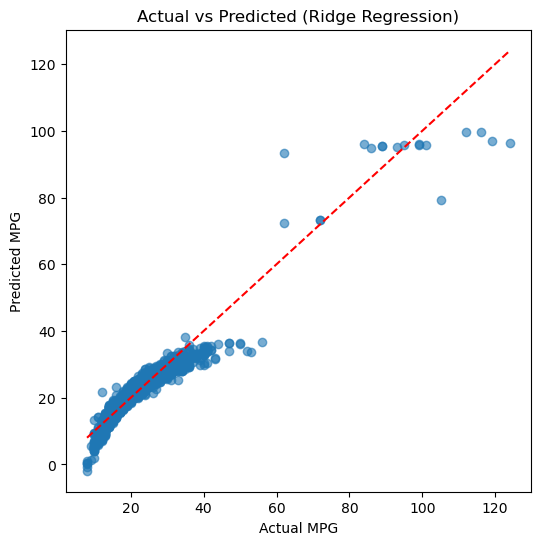

In [99]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_predl2, alpha=0.6)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linestyle='--')

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted (Ridge Regression)")
plt.show()

##### Ridge Regression (L2)
- Most predictions are close to the ideal line.
- Prediction accuracy is better than Lasso.
- High-MPG vehicles are predicted more accurately than Lasso.
- Ridge provides a stable and well-generalized model.

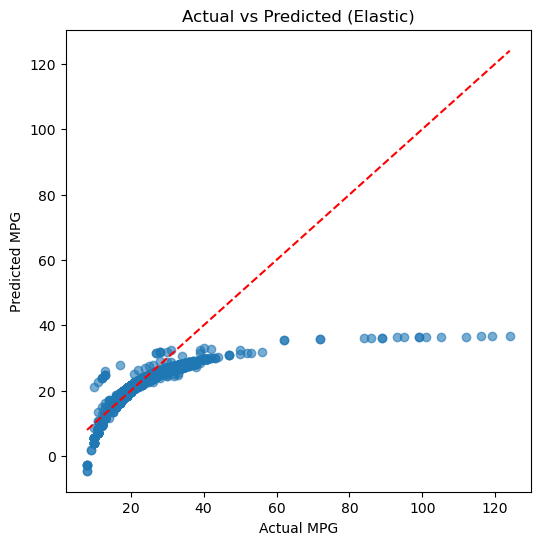

In [100]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_predl12, alpha=0.6)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linestyle='--')

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted (Elastic)")
plt.show()

##### ElasticNet Regression
- The model performs better than Lasso but is similar to Ridge.
- Some high-MPG vehicles are still under-predicted.
- Prediction accuracy is good but slightly lower than Ridge.
- ElasticNet provides balanced regularization.

#### Overall Comparison

- Linear Regression and Ridge Regression show the best prediction performance.
- Ridge Regression provides more stable predictions with better generalization.
- Lasso Regression has the highest prediction errors because it removes less important features.
- ElasticNet balances L1 and L2 regularization but does not outperform Ridge on this dataset.
- Linear Regression is selected as the final model because it achieves the best balance between accuracy and generalization.

### Final Conclusion

- Built a regression model to predict **Combined MPG**.
- Used **ColumnTransformer + One-Hot Encoding** for preprocessing.
- Trained and compared **Linear, Ridge, Lasso, and ElasticNet Regression** models.
- Evaluated models using **R², MAE, MSE, RMSE, and MAPE**.
- **Linear Regression** performed the best with an **R² score of approximately 0.93**.
- The model provides accurate and reliable predictions for most vehicles.